# 4.1 Primary outcome - simple diff in diff analysis

This notebook does the following:
    - OLS analysis of secondary outcomes - climate attitudes and top-down vs bottom-up attitude

## Set-up

In [1]:
# Set-up
import pandas as pd
import numpy as np
import sys
import re
import textwrap
import importlib
from pathlib import Path
import matplotlib.pyplot as plt
CODE_ROOT = Path.cwd().parents[1]
sys.path.append(str(CODE_ROOT))
import configW2 as config
import os
import statsmodels.formula.api as smf
import pyfixest as pf

sys.path.append(str(Path.cwd().parents[1] / "3_Analysis/functions"))
from make_regression_table import make_regression_table

# Font settings for plots
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]
plt.rcParams["font.size"] = 16

In [2]:
## Load in both code files such that it can be concatinated
df = pd.read_csv(
    config.CLEAN_DATA / "merged_wave_final_dataset.csv", 
    keep_default_na=False, # Keep "None" as a string, not NaN
    na_values=[""] # Only treat empty strings as NaN
)

In [3]:
# Construct post variable
df["post"] = (df["survey"] == "EL").astype(int)

In [4]:
# Keep only labgroups that have both pre and post observations
labgroup_counts = df.groupby("labgroupid")["survey"].nunique()
labgroups_to_keep = labgroup_counts[labgroup_counts == 2].index
df = df[df["labgroupid"].isin(labgroups_to_keep)].copy()

## (1) Prepare dataset

In [5]:
# Create baseline_energy_use variable
df["baseline_energy_use"] = df.groupby("labgroupid")["annual_electricity_total_mwh"].transform(
    lambda x: x[df["survey"] == "BL"].iloc[0]
)

# Log transform the baseline_energy_use variable
df["log_baseline_energy_use"] = np.log(df["baseline_energy_use"])

# Log transform group size - no_researchers is heavily right-skewed
df["log_no_researchers"] = np.log(df["no_researchers"])

In [6]:
# Keep only one row per labgroupid - we will use the EL observation
df = df[df["survey"] == "EL"].copy()

In [7]:
print(df.groupby("faculty")["labgroupid"].nunique())

faculty
Both MNF and MeF              5
Both VetSuisse and MNF        1
Faculty of Medicine (MeF)    27
Faculty of Science (MNF)     79
VetSuisse                     4
Name: labgroupid, dtype: int64


In [8]:
# Create mnf_indicator variable
df["mnf_indicator"] = df["faculty"].apply(lambda x: 1 if x == "Faculty of Science (MNF)" else 0).astype(int)

In [9]:
# Recode attitude responses to numeric scale
attitude_map = {
    "Strongly disagree": 1,
    "Disagree": 2,
    "Neither agree nor disagree": 3,
    "Agree": 4,
    "Strongly agree": 5,
}

# Keep attitude variables in numerical order
attitude_cols = sorted(
    [c for c in df.columns if c.startswith("attitude_q_")],
    key=lambda x: int(re.search(r"(\d+)$", x).group(1))
)

In [10]:
# Check whether any labs that answer one attitude q but have missing values for another attitude q
for att_q in attitude_cols:
    missing_att_q = df[df[att_q].isna()]["labgroupid"]
    for other_att_q in attitude_cols:
        if other_att_q != att_q:
            missing_other_att_q = df[df[other_att_q].isna()]["labgroupid"]
            if not missing_att_q.equals(missing_other_att_q):
                print(f"Warning: Labs with missing {att_q} do not match labs with missing {other_att_q}")

In [11]:
# Restrict to labs with non-missing values for all attitude questions
df = df.dropna(subset=attitude_cols).copy()

## (2) Regressions

### (2a) No enumerator FEs

In [12]:
# Define regression formula

# Control vars
control_vars = [
    "log_no_researchers",
    "log_baseline_energy_use",
    "mnf_indicator",
]

# Independent vars
ind_vars = "treated + " + " + ".join(control_vars)
print(ind_vars)

## One group is missing their researcher count and must be excluded
df = df.dropna(subset=control_vars).copy()

treated + log_no_researchers + log_baseline_energy_use + mnf_indicator


In [13]:
# Regressions without enumerator FEs
fit_attitudes = {}

for att_q in attitude_cols:

    # Map attitude responses to numeric scale for regression
    df["y"] = df[att_q].map(attitude_map)

    formula = f"y ~ {ind_vars}"
    model = smf.ols(formula=formula, data=df)
    fit_attitudes[att_q] = model.fit(cov_type="cluster", cov_kwds={"groups": df["enum_id"]})
    print(f"Finished regression for {att_q}")
    print(fit_attitudes[att_q].summary())

Finished regression for attitude_q_1
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                 -0.024
Method:                 Least Squares   F-statistic:                    0.3649
Date:                Wed, 28 Oct 2026   Prob (F-statistic):              0.832
Time:                        12:54:45   Log-Likelihood:                -110.42
No. Observations:                  99   AIC:                             230.8
Df Residuals:                      94   BIC:                             243.8
Df Model:                           4                                         
Covariance Type:              cluster                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

### (2b) With enumerator FEs

In [14]:
# Restrict data to enums that are non-singleton and have both treated and control labs
all_enums = df["enum_id"].unique()

enum_counts = df["enum_id"].value_counts()
singleton_enums = enum_counts[enum_counts == 1].index

enum_t_labs = df[df["treated"] == 1]["enum_id"].unique()
enum_c_labs  = df[df["treated"] == 0]["enum_id"].unique()

# Enums that only appear in treated or only in control labs
no_t_enums = all_enums[~np.isin(all_enums, enum_t_labs)]
no_c_enums = all_enums[~np.isin(all_enums, enum_c_labs)]

enums_to_exclude = set(singleton_enums) | set(no_t_enums) | set(no_c_enums)
enum_fe_df = df[~df["enum_id"].isin(enums_to_exclude)].copy()

print(f"Enums excluded: {len(enums_to_exclude)}. This comprises: singletons: {len(singleton_enums)}, T-only: {len(no_t_enums)}, C-only: {len(no_c_enums)}")
print(f"Rows remaining: {len(enum_fe_df)} of {len(df)}")

Enums excluded: 9. This comprises: singletons: 6, T-only: 2, C-only: 7
Rows remaining: 86 of 99


In [15]:
# Regressions with enumerator FEs
fit_attitudes_enum_fe = {}

for att_q in attitude_cols:

    # Map attitude responses to numeric scale for regression
    enum_fe_df["y"] = enum_fe_df[att_q].map(attitude_map)

    fit_attitudes_enum_fe[att_q] = pf.feols(
                "y ~ treated + log_no_researchers + mnf_indicator + log_baseline_energy_use | enum_id",
                data=enum_fe_df,
                vcov={"CRV1": "enum_id"}
            )
    print(fit_attitudes_enum_fe[att_q].summary())

###

Estimation:  OLS
Dep. var.: y, Fixed effects: enum_id
sample: None = all
Inference:  CRV1
Observations:  86

| Coefficient             |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:------------------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| treated                 |     -0.086 |        0.123 |    -0.699 |      0.492 | -0.341 |   0.170 |
| log_no_researchers      |     -0.032 |        0.111 |    -0.290 |      0.775 | -0.263 |   0.199 |
| mnf_indicator           |      0.194 |        0.221 |     0.877 |      0.390 | -0.266 |   0.655 |
| log_baseline_energy_use |      0.007 |        0.082 |     0.087 |      0.932 | -0.164 |   0.178 |
---
RMSE: 0.613 R2: 0.359 R2 Within: 0.02 
None
###

Estimation:  OLS
Dep. var.: y, Fixed effects: enum_id
sample: None = all
Inference:  CRV1
Observations:  86

| Coefficient             |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:----------------------

## (3) Make regression tables

In [16]:
# Column names
col_subgroups = {
        "University responsibility":         [0],
        "Excess energy use": [1],
        "Try consider sustainability":        [2],
        "Slow down research":       [3],
        "Improve research quality":           [4],
        "Awareness of energy costs":      [5],
        "Financial motivation":           [6],
        "Top-down more effective":     [7],
    }

In [17]:
# Multiple hypothesis testing correction across the 7 attitude items (no-enum-FE spec),
# excluding awareness (attitude_q_6) - treated as a separate hypothesis family, see 4_6.
# BH controls the false discovery rate (standard for an outcome battery like this); Holm
# controls the familywise error rate and is more conservative - reporting both.
from statsmodels.stats.multitest import multipletests

mht_cols = [q for q in attitude_cols if q != "attitude_q_6"]
raw_pvals = [fit_attitudes[q].pvalues["treated"] for q in mht_cols]

_, bh_q, _, _ = multipletests(raw_pvals, method="fdr_bh")
_, holm_p, _, _ = multipletests(raw_pvals, method="holm")

bh_map = dict(zip(mht_cols, bh_q))
holm_map = dict(zip(mht_cols, holm_p))

mht_summary = pd.DataFrame({
    "Question": mht_cols,
    "Raw p": raw_pvals,
    "BH q-value": [bh_map[q] for q in mht_cols],
    "Holm p-value": [holm_map[q] for q in mht_cols],
}).round(3)
print(mht_summary)

# attitude_q_6 (awareness) gets None -> blank cell in the table
bh_row = [bh_map.get(q) for q in attitude_cols]
holm_row = [holm_map.get(q) for q in attitude_cols]

       Question  Raw p  BH q-value  Holm p-value
0  attitude_q_1  0.999       0.999         1.000
1  attitude_q_2  0.470       0.822         1.000
2  attitude_q_3  0.448       0.822         1.000
3  attitude_q_4  0.968       0.999         1.000
4  attitude_q_5  0.050       0.174         0.299
5  attitude_q_7  0.032       0.174         0.224
6  attitude_q_8  0.659       0.922         1.000


In [18]:
# Create regression table without enumerator FEs
table = make_regression_table(
    fit_list    = [fit_attitudes[q] for q in attitude_cols],
    model_names = [f"({i+1})" for i in range(len(attitude_cols))],
    keep_vars   = ["treated"],
    var_labels  = {"treated": "Treated"},
    col_subgroups = col_subgroups,
    fe_rows     = None,
    baseline_mean = None,
    decimals      = 3,
    r2_type       = None,
    wcb_pvals     = bh_row,
    ri_pvals      = holm_row,
    wcb_label     = "BH $q$-value",
    ri_label      = "Holm $p$-value",
    col1_width    = "4cm",
    coln_width    = "2cm",
)
table_path = config.OUTPUT / "5_Regression_Tables" / "secondary_attitudes_no_enum_fe.tex"
_ = table_path.write_text(table)

In [19]:
# Create regression table with enumerator FEs
table = make_regression_table(
    fit_list    = [fit_attitudes_enum_fe[q] for q in attitude_cols],
    model_names = [f"({i+1})" for i in range(len(attitude_cols))],
    keep_vars   = ["treated"],
    var_labels  = {"treated": "Treated"},
    col_subgroups = col_subgroups,
    fe_rows     = {
        "Enumerator FE": [True] * len(attitude_cols),
    },
    baseline_mean = None,
    decimals      = 3,
    r2_type       = None,
    col1_width    = "4cm",
    coln_width    = "2cm",
)
table_path = config.OUTPUT / "5_Regression_Tables" / "secondary_attitudes_enum_fe.tex"
_ = table_path.write_text(table)

## (4) Coefficient plot

In [20]:
# Question labels (same order as attitude_cols)
question_labels = [
    "Universities have a responsibility to reduce their environmental impact",
    "Research groups consume more energy/resources than necessary",
    "I try to consider sustainability when making decisions in my group",
    "Sustainability requirements risk slowing down scientific research",
    "Sustainable research practices can improve research quality/efficiency",
    "I am aware of the energy/resource costs of my group's activities",
    "I would be more motivated if my group directly faced the financial costs",
    "Top-down initiatives are more effective than bottom-up ones",
]

In [21]:
# Extract treatment coefficients and SEs from the no-enum-FE regressions
coef_rows = []
for i, q in enumerate(attitude_cols):
    fit = fit_attitudes[q]
    coef_rows.append({
        "q_num":    i + 1,
        "Outcome":  q,
        "Question": textwrap.fill(question_labels[i], width=45),
        "Coef":     fit.params["treated"],
        "SE":       fit.bse["treated"],
        "p":        fit.pvalues["treated"],
    })

coef_df = pd.DataFrame(coef_rows)
coef_df["CI95"] = 1.96 * coef_df["SE"]
coef_df

,q_num,Outcome,Question,Coef,SE,p,CI95
0,1,attitude_q_1,Universities have a responsibility to reduce\n...,-0.000151,0.124205,0.999028,0.243442
1,2,attitude_q_2,Research groups consume more energy/resources\...,0.105604,0.146069,0.469694,0.286295
2,3,attitude_q_3,I try to consider sustainability when making\n...,0.115099,0.151628,0.447799,0.297191
3,4,attitude_q_4,Sustainability requirements risk slowing down\...,0.008511,0.209428,0.967584,0.410478
4,5,attitude_q_5,Sustainable research practices can improve\nre...,0.328292,0.167320,0.049756,0.327948
5,6,attitude_q_6,I am aware of the energy/resource costs of my\...,0.314985,0.185940,0.090263,0.364443
6,7,attitude_q_7,I would be more motivated if my group\ndirectl...,-0.419874,0.195837,0.032033,0.383840
7,8,attitude_q_8,Top-down initiatives are more effective than\n...,0.084352,0.190890,0.658571,0.374145


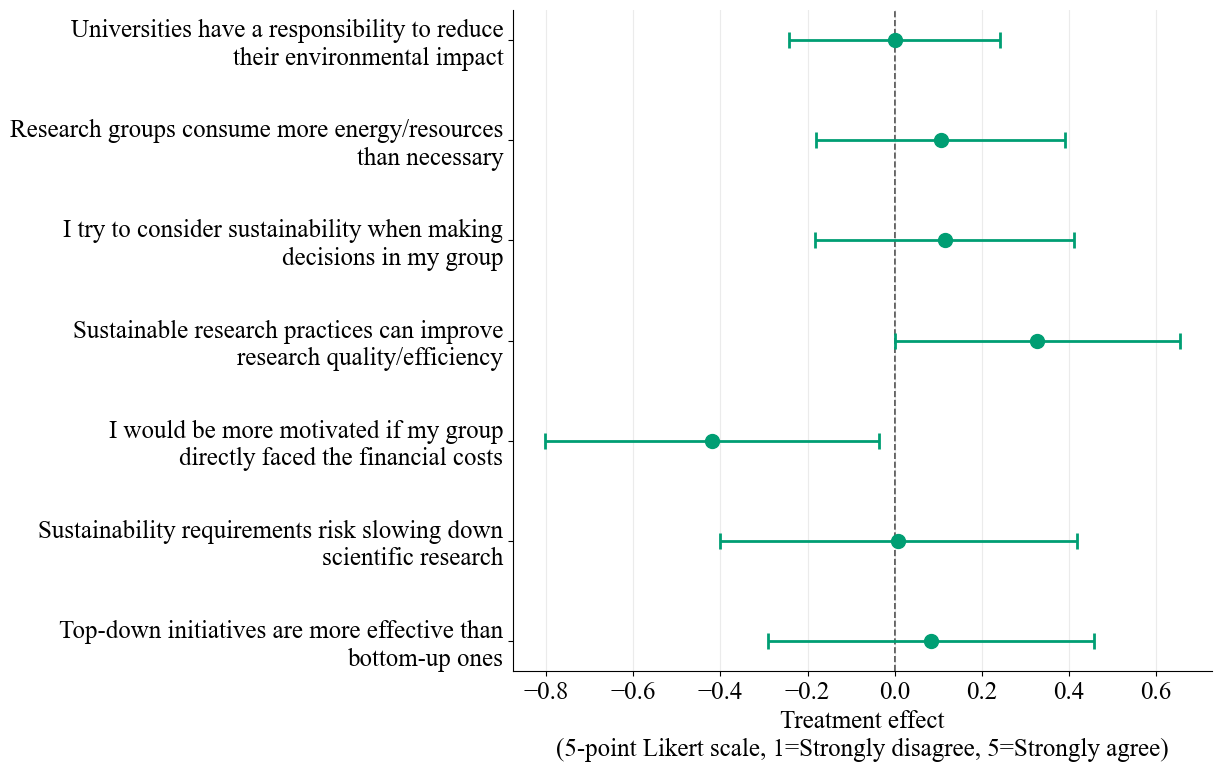

In [22]:
# Coefficient plot (no enumerator FEs)
# - Drop the awareness question (attitude_q_6) - it's a factual awareness check, not an attitude
# - Reorder so the two negatively-framed items (risk of sustainability requirements slowing
#   research; top-down more effective than bottom-up) sit at the bottom, other items keep
#   their original order
# - Bluish-green (#009E73, Okabe-Ito), matching the project's single-series default (see
#   3_Analysis/functions/histogram_truncated_func.r's overall_colour - blue/vermillion is
#   reserved there for a two-group treated/control breakdown, which this plot doesn't have)
plot_order = ["attitude_q_1", "attitude_q_2", "attitude_q_3", "attitude_q_5", "attitude_q_7", "attitude_q_4", "attitude_q_8"]
plot_df = coef_df[coef_df["Outcome"] != "attitude_q_6"].copy()
plot_df["Outcome"] = pd.Categorical(plot_df["Outcome"], categories=plot_order, ordered=True)
plot_df = plot_df.sort_values("Outcome").reset_index(drop=True)

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(12.5, 8))

ax.errorbar(
    plot_df["Coef"],
    y,
    xerr=plot_df["CI95"],
    fmt="o",
    color="#009E73",
    ecolor="#009E73",
    elinewidth=2,
    capsize=6,
    capthick=2,
    markersize=10,
    zorder=3,
)

ax.axvline(0, color="#444444", linestyle="--", linewidth=1.2, zorder=1)
ax.set_yticks(y)
ax.set_yticklabels(plot_df["Question"], fontsize=18)
ax.invert_yaxis()
ax.set_xlabel(
    "Treatment effect\n(5-point Likert scale, 1=Strongly disagree, 5=Strongly agree)",
    fontsize=18,
)
ax.tick_params(axis="x", labelsize=18)
ax.grid(axis="x", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

output_folder = config.OUTPUT / "5_Regression_Tables"
output_folder.mkdir(parents=True, exist_ok=True)
plt.savefig(output_folder / "secondary_attitudes_coef_plot.pdf", bbox_inches="tight")
plt.show()